# Figure 2：Pathway Enrichment Analysis of DEGs in Tg3 versus WT3 in the Xenium Alzheimer’s Disease Dataset

In [1]:
suppressPackageStartupMessages({
  library(ggplot2)
  library(dplyr)
  library(Matrix)
  library(stringr)
  library(clusterProfiler)
  library(org.Mm.eg.db)
  library(msigdbr)
})

In [2]:
deg_df <- read.csv('./Outputs/Microglia_DEG_Tg3_vs_WT3.csv', check.names = F)
head(deg_df)

,names,scores,logfoldchanges,pvals,pvals_adj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,Gfap,25.96259,5.5260550,1.310679e-148,4.548055e-146
2,Lyz2,17.11105,3.2263358,1.227673e-65,2.130012e-63
3,Apoe,13.51286,0.9319684,1.313290e-41,9.114235e-40
4,Vim,13.19587,3.5882268,9.267240e-40,4.593903e-38
5,Ctsb,11.97290,0.9730375,4.927707e-33,2.137393e-31
6,C4b,11.69448,3.6046352,1.360221e-31,5.244406e-30


In [3]:
markers_tg3 <- deg_df$names[deg_df$logfoldchanges > 0.2 & deg_df$pvals_adj < 0.05]
markers_wt3 <- deg_df$names[deg_df$logfoldchanges < -0.2 & deg_df$pvals_adj < 0.05]
length(markers_tg3)
length(markers_wt3)

run_enrichment <- function(markers){
  entrez_genes <- bitr(markers, fromType="SYMBOL", toType="ENTREZID", OrgDb=org.Mm.eg.db)
  go_bp <- enrichGO(gene = entrez_genes$ENTREZID, OrgDb = org.Mm.eg.db, keyType = "ENTREZID", ont = "BP",
                    pvalueCutoff = 0.05, qvalueCutoff = 0.05, readable=TRUE)
  subset(go_bp@result, p.adjust < 0.05 & qvalue < 0.05 & Count > 2)
}

gobp_tg3 <- run_enrichment(markers_tg3)
gobp_wt3 <- run_enrichment(markers_wt3)

[1] 39

[1] 41

'select()' returned 1:1 mapping between keys and columns

'select()' returned 1:1 mapping between keys and columns



In [4]:
gobp_tg3_display <- gobp_tg3[c(1, 4, 5, 8, 10, 11, 21, 26, 38, 55, 65, 66, 105, 149, 150), ]
# pathway_tg3 <- c("antigen processing and presentation", "negative regulation of neuron projection development", "amyloid fibril formation", "negative regulation of neurogenesis", "negative regulation of nervous system development", "negative regulation of neuron differentiation", "positive regulation of endocytosis", "regulation of neuron death", "neuroinflammatory response", "positive regulation of cell killing", "cytokine-mediated signaling pathway", "amyloid-beta clearance", "amyloid-beta metabolic process", "regulation of reactive oxygen species metabolic process", "regulation of cytokine production involved in immune response")
# gobp_tg3_display <- gobp_tg3[which(gobp_tg3$Description %in% pathway_tg3), ]
gobp_tg3_display$Direction <- 'Tg3'

gobp_wt3_display <- gobp_wt3[c(1, 2, 10, 7, 54, 68), ]
# pathway_tg3 <- c("learning or memory", "cognition", "vesicle-mediated transport in synapse", "forebrain development", "neurotransmitter transport", "regulation of neurotransmitter secretion")
# gobp_wt3_display <- gobp_wt3[which(gobp_wt3$Description %in% pathway_tg3), ]
gobp_wt3_display$Direction <- 'WT3'

gobp_df <- rbind(gobp_tg3_display, gobp_wt3_display)
gobp_df$GeneRatio <- sapply(strsplit(as.character(gobp_df$GeneRatio), "/"),
                            function(x) as.numeric(x[1]) / as.numeric(x[2]))
gobp_df$log_padj <- -log10(gobp_df$p.adjust)
gobp_df$Description <- paste0(toupper(substr(gobp_df$Description, 1, 1)),
                              tolower(substr(gobp_df$Description, 2, nchar(gobp_df$Description))))
gobp_df$Direction <- factor(gobp_df$Direction, levels=c("Tg3", "WT3"), ordered=TRUE)
gobp_df <- gobp_df[order(gobp_df$Direction, gobp_df$GeneRatio), ]

write.csv(gobp_df, "./Outputs/Microglia_GOBP_Enrichment_pathway.csv")
gobp_df

,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count,Direction,log_padj
,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<ord>,<dbl>
GO:0097242,GO:0097242,Amyloid-beta clearance,0.07894737,36/23328,2.743355e-05,7.619044e-04,3.771566e-04,Apoe/Trem2/Clu,3,Tg3,3.118100
GO:0050435,GO:0050435,Amyloid-beta metabolic process,0.07894737,53/23328,8.830443e-05,1.527000e-03,7.558929e-04,Apoe/Igf1/Clu,3,Tg3,2.816161
GO:0002718,GO:0002718,Regulation of cytokine production involved in immune response,0.07894737,85/23328,3.591727e-04,4.039040e-03,1.999398e-03,Cd74/B2m/Fcer1g,3,Tg3,2.393722
GO:1990000,GO:1990000,Amyloid fibril formation,0.10526316,18/23328,1.801295e-08,6.603549e-06,3.268877e-06,Apoe/B2m/Gsn/Clu,4,Tg3,5.180223
GO:0150076,GO:0150076,Neuroinflammatory response,0.10526316,70/23328,5.079786e-06,2.442650e-04,1.209156e-04,Tyrobp/Trem2/Igf1/Clu,4,Tg3,3.612139
GO:0031343,GO:0031343,Positive regulation of cell killing,0.10526316,95/23328,1.713094e-05,5.709276e-04,2.826196e-04,Tyrobp/B2m/H2-D1/H2-K1,4,Tg3,3.243419
GO:2000377,GO:2000377,Regulation of reactive oxygen species metabolic process,0.10526316,207/23328,3.509481e-04,3.970912e-03,1.965674e-03,Tyrobp/Igf1/Stat3/Clu,4,Tg3,2.401110
GO:0045807,GO:0045807,Positive regulation of endocytosis,0.13157895,122/23328,1.574892e-06,1.312171e-04,6.495486e-05,Apoe/Cd63/B2m/Trem2/Clu,5,Tg3,3.882010
GO:0019221,GO:0019221,Cytokine-mediated signaling pathway,0.15789474,369/23328,2.707224e-05,7.619044e-04,3.771566e-04,Cd74/Fcer1g/Trem2/Stat3/Ifitm3/Osmr,6,Tg3,3.118100


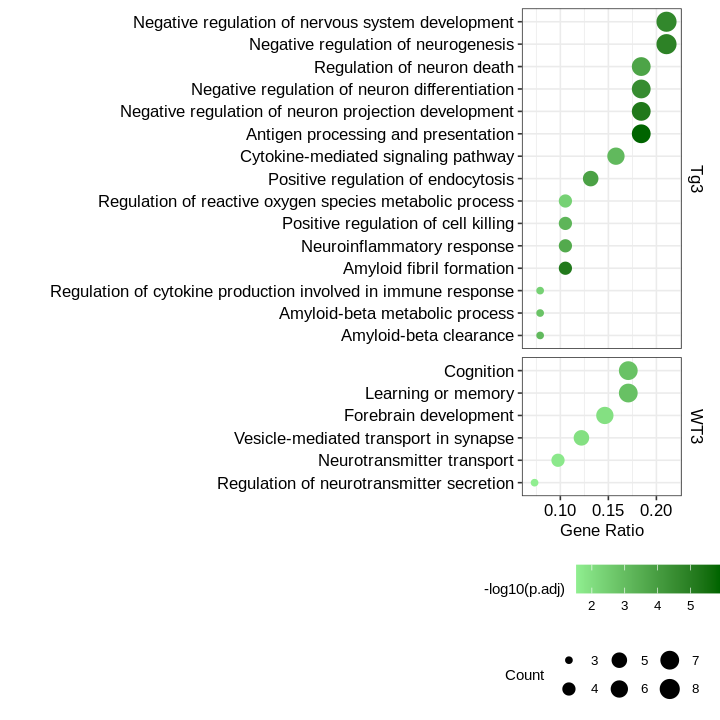

In [5]:
library(ggplot2)
gobp_df$Description_plot <- paste0(gobp_df$Direction, "___", gobp_df$Description)
gobp_df$Description_plot <- factor(gobp_df$Description_plot,
                                   levels=unique(gobp_df$Description_plot))

p1 <- ggplot(gobp_df, aes(x=GeneRatio, y=Description_plot)) +
  geom_point(aes(size=Count, color=log_padj)) +
  facet_grid(Direction ~ ., scales="free_y", space="free_y") +
  scale_x_continuous(limits=c(0.06, 0.22), expand=expansion(mult=c(0, 0.04))) +
  scale_y_discrete(labels=function(x) sub("^.*___", "", x)) +
  scale_color_gradient(low="lightgreen", high="darkgreen", name="-log10(p.adj)") +
  scale_size_continuous(name="Count", range=c(1.5, 5)) +
  labs(x="Gene Ratio", y="") +
  theme_bw(base_size=10) +
  theme(axis.text.x=element_text(size=10, color="black"),
        axis.text.y=element_text(size=10, color="black"),
        axis.title.y=element_text(size=10, color="black"),
        legend.position="bottom", legend.box="vertical",
        legend.title=element_text(size=9, color="black"),
        legend.text=element_text(size=8, color="black"),
        plot.title=element_text(color="black"),
        plot.subtitle=element_text(color="black"),
        strip.background=element_blank(),
        strip.text=element_text(size=10, color="black"))

options(repr.plot.width=6, repr.plot.height=6)
print(p1)

# pdf("Microglia_GOBP_Enrichment_pathway_dotplot.pdf", width = 6, height = 6)
# print(p1)
# dev.off()